# Flux: NEE of the LI-7500 years compared with FLUXNET and Etzold et al. (2011)

# About this notebook

The annual net ecosystem exchange of CO2 (`NEE`) of the open-path LI-7500 (`IRGA75`) years of this
product is less negative than in two earlier estimates for the same years: the FLUXNET release
ONEFlux v1.3 for CH-Lae, and Etzold et al. (2011, Ecosystems 14:1289-1309) for 2005-2009. This
notebook compares the three, splits the difference to FLUXNET by the kind of half-hour it comes
from, and recomputes the self-heating correction that Etzold et al. (2011) used, so that it can be
applied to the flux of this product in place of its own correction. It computes no product.

**Which run is shown.** The notebook reads the outputs of the `IRGA75` flux chain as they are on
disk, so a rerun of the chain refreshes every number below. The modification time of each input
file is printed under *Load data*; the numbers belong to the run of that date.

**Sign convention and units.** `NEE` is negative when the forest takes up CO2. Half-hourly values
and corrections are in µmol CO2 m⁻² s⁻¹; sums are in gC m⁻² (1 µmol m⁻² s⁻¹ over 30 minutes is
0.0216 gC m⁻²). A correction is stated as the amount it **adds** to the uncorrected flux, so a
positive correction reduces the uptake.

**Columns used**

- This product, `IRGA75` (`30_FLUX_POST-PROCESSING_CHAIN/IRGA75/05_FPPC_IRGA75_NEE_OPCO_2004-2017`):
  - `NEE_L3.1_L3.3_CUT_50_QCF_gfXG` — `NEE` after all quality tests, filtered at the median USTAR
    threshold (`CUT_50`) and gap-filled with XGBoost. The main series, called *ours* below
  - `FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED` — `0` measured, `1` gap-filled
  - `NEE_L3.1_L3.2_QCF` — `NEE` after the outlier tests and before the USTAR filter
  - `NIGHTTIME` — the night flag of this product, used for the `IRGA72` reference only
- The input of the chain (`.../IRGA75/01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019`):
  - `FC` — the CO2 flux of the LI-7500 **without** the self-heating correction
  - `BIAS_OPCO` — the bias modelled by opco; `FC_L1.1_OPCO = FC - BIAS_OPCO` is the corrected flux,
    so the opco correction adds `-BIAS_OPCO`
  - `SC_SINGLE` — storage flux from the single-point profile
  - `CO2_MOLAR_DENSITY` (mmol m⁻³), `WS`, `USTAR`, `T_SONIC` (°C), `VAPOR_DENSITY`, `AIR_DENSITY`
    (kg m⁻³) — the inputs of the correction of Burba et al. (2008)
- The LI-7200 (`IRGA72`, `.../IRGA72/05_FPPC_IRGA72_NEE_2016-2026.09`): the same main series and
  flag, as the reference not affected by self-heating, 2016-2025
- FLUXNET (`EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1`, `-9999` is missing):
  - `NEE_VUT_REF` — `NEE` with the variable USTAR threshold, reference scenario
  - `NEE_VUT_REF_QC` — `0` measured, above `0` gap-filled
  - `NIGHT` — `1` at night
  - the annual sums `NEE_VUT_REF` of the `YY` file, to check the sums computed here

**Day and night.** The comparisons with FLUXNET and with Etzold et al. (2011) split the records
by the FLUXNET flag `NIGHT`, so that both products are split the same way. The `NIGHTTIME` flag of
this product marks about 2 % more records as night, at dusk and dawn; it is used only for the
`IRGA72` years after 2024, which FLUXNET does not cover.

**Timestamps.** This product is stored on `TIMESTAMP_MIDDLE`, FLUXNET on `TIMESTAMP_START`; the
FLUXNET timestamps are moved forward by 15 minutes before the two are joined. Both are in CET
(UTC+01:00).

**2004 is incomplete.** FLUXNET starts on 14 March 2004 and the measurements of this product on
31 March 2004; the main series of this product is gap-filled from 1 January. Comparisons with
FLUXNET use only the half-hours FLUXNET covers.

# Main findings

The numbers behind each point are in the tables below.

- **Shared measured half-hours.** Where both products measured, they agree closely by day. At
  night this product is higher, because its correction adds more at night than the correction that
  is implied in FLUXNET.
- **Gap-filled nights.** The largest part of the annual difference to FLUXNET in 2004-2015 comes
  from the nights that both products gap-fill. FLUXNET fills the winter nights far below this
  product, in line with its low measured winter nights. The winter nights of the LI-7200 years are
  close to this product and well above FLUXNET.
- **2016 and 2017.** FLUXNET uses the LI-7200 in these years and differs from the LI-7200 sums of
  this product in the other direction. The cause is not investigated here.
- **Etzold et al. (2011).** The processing step that differs most is the self-heating correction.
  The correction of Burba et al. (2008), with the fraction of Järvi et al. (2009), is much smaller
  than opco by day in every month and over the year. Applied to the flux of this product in place of opco, it gives
  an annual sum and a seasonal pattern close to those that Etzold et al. (2011) report.
- **What the LI-7200 decides.** In winter the LI-7200 years agree with the opco-corrected flux,
  not with the smaller correction. In summer, in the run shown, they lie between the two. Whether
  opco is too large in the summers of the early years remains open.
- **Approximations.** Removing opco and adding the other correction uses the mean correction of
  each calendar month, by day and by night, applied to every half-hour, measured or gap-filled.
  The values of Etzold et al. (2011) per month are read from a figure.

</br>

# Settings

In [1]:
# This product. The flux chain's outputs are read as they are on disk, so a rerun of the chain
# refreshes every number in this notebook.
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow\30_FLUX_POST-PROCESSING_CHAIN")
FILE_NEE75 = r"IRGA75\05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet"
FILE_INPUT75 = r"IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet"
FILE_NEE72 = r"IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet"

varname = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG'  # the main series
flagname = 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'  # 0 measured, 1 gap-filled
varname_l32 = 'NEE_L3.1_L3.2_QCF'  # after the outlier tests, before the USTAR filter
NIGHTTIME = 'NIGHTTIME'
# FC is the uncorrected LI-7500 flux; FC_L1.1_OPCO = FC - BIAS_OPCO is the corrected one.
INPUT_COLS = ['FC', 'FC_L1.1_OPCO', 'BIAS_OPCO', 'SC_SINGLE', 'CO2_MOLAR_DENSITY', 'WS', 'USTAR',
              'T_SONIC', 'VAPOR_DENSITY', 'AIR_DENSITY']

# FLUXNET ONEFlux v1.3 for CH-Lae. Missing values are -9999; timestamps are TIMESTAMP_START.
FLUXNET_DIR = r"F:\Sync\luhk_work\sites\LAE\Data\Datasets\EUF_CH-Lae_FLUXNET_2004-2024_v1.3_r1"
FLUXNET_HH = "EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1.csv"
FLUXNET_YY = "EUF_CH-Lae_FLUXNET_FLUXMET_YY_2004-2024_v1.3_r1.csv"
FLX_NEE, FLX_QC, FLX_NIGHT = 'NEE_VUT_REF', 'NEE_VUT_REF_QC', 'NIGHT'
FLX_MISSING = -9999

# Periods.
FIRST_YEAR, LAST_YEAR = 2004, 2017  # the LI-7500 record of this product
LI7500_ONLY = (2004, 2015)  # the LI-7500 is the only analyser
PARALLEL_YEARS = (2016, 2017)  # both analysers; FLUXNET uses the LI-7200
IRGA72_YEARS = (2016, 2025)  # full LI-7200 years of this product, the reference
ETZOLD_YEARS = (2005, 2009)  # the years of Etzold et al. 2011

# Published values of Etzold et al. 2011 (Ecosystems 14:1289-1309), declared here because they
# are not in any data file.
ETZOLD_MEAN = -415  # mean annual NEE 2005-2009, gC m-2 y-1; p. 1301 and Table 4
ETZOLD_RANGE = (-662, -366)  # most and least negative year, gC m-2 y-1; p. 1301 and Table 4
# Mean monthly NEE 2005-2009 in gC m-2, read by eye from Fig. 5 of Etzold et al. 2011, accurate
# to about +-10 gC m-2. The five winter months are the least certain: each lies between about
# +20 and +45, and +35 is used for all five.
ETZOLD_FIG5 = {1: 35, 2: 35, 3: 35, 4: -5, 5: -110, 6: -155, 7: -138, 8: -105, 9: -62, 10: 5,
               11: 35, 12: 35}
ETZOLD_FIG5_ACCURACY = 10
ETZOLD_FIG5_WINTER_RANGE = (20, 45)  # the range read for each of the five winter months
ETZOLD_FIG5_LEAST_CERTAIN = [11, 12, 1, 2, 3]
# Processing of Etzold et al. 2011, p. 1297.
ETZOLD_METHODS = {
    'density correction': "WPL",
    'self-heating correction': "Burba et al. (2008), with the surface temperatures and fraction "
                               "of Järvi et al. (2009)",
    'large winter fluxes (±15 µmol m-2 s-1)': "kept in the data, excluded from the gap-filling fits",
    'negative nighttime values': "removed, together with as many positive ones (trimmed)",
    'gap-filling': "light response by day, Lloyd-Taylor at night, running mean below 0 °C",
    'USTAR threshold (m s-1)': "0.3",
    'measured nights (%)': "24",
}
# This product, from docs/L1.1.md, docs/L3.2.md, docs/L3.3.md and docs/L4.1.md.
USTAR_CUT_50 = 0.304  # m s-1, the CUT_50 threshold of both analysers; docs/L3.3.md
PRODUCT_METHODS = {
    'density correction': "WPL, in EddyPro (Level 1)",
    'self-heating correction': "opco: heating and WPL thermal terms with coefficients fitted to "
                               "the LI-7200 in 2016-2017 (Level 1.1)",
    'large winter fluxes (±15 µmol m-2 s-1)': "absolute limits ±50 µmol m-2 s-1 and outlier tests "
                                              "(Level 3.2)",
    'negative nighttime values': "removed where clearly below zero: single records and whole "
                                 "nights (Level 3.2)",
    'gap-filling': "XGBoost (Level 4.1)",
    'USTAR threshold (m s-1)': f"{USTAR_CUT_50} (CUT_50, constant)",
}

# The correction of Burba et al. 2008 with the fraction of Jarvi et al. 2009, as in an R
# implementation used in the group.
BURBA_FRACTION = 0.085
M_AIR, M_H2O = 0.028965, 0.018  # kg mol-1

# Seasons of the comparison with Etzold et al. 2011.
SEASONS = {'Nov-Mar': [11, 12, 1, 2, 3], 'Apr+Oct': [4, 10], 'May-Sep': [5, 6, 7, 8, 9]}
USTAR_BINS = [0, 0.1, 0.2, 0.3, 0.4, 0.6, 5]  # m s-1, for the nights by USTAR

units = "µmol m-2 s-1"
units_sum = "gC m-2"
UMOL_TO_GC = 12.011 * 1e-6 * 1800  # umol CO2 m-2 s-1 over one half-hour -> gC m-2
CLASSES = {'A': 'both measured', 'B': 'ours measured only', 'C': 'FLUXNET measured only',
           'D': 'both filled'}
COLORS = {'ours': '#1E88E5', 'FLUXNET': '#FB8C00', 'IRGA72': '#43A047', 'study2011': '#212121',
          'burba': '#8E24AA', 'noopco': '#90A4AE'}

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
version_diive = importlib.metadata.version("diive")
print(f"diive version: v{version_diive}")

diive version: v0.93.0


# Helpers

In [3]:
def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure — {text}", width), fontsize=9, ha='left', x=0.005)


def styled(data, caption, fmt="{:.0f}", subset=None, cmap="RdBu_r", axis=None, center=True):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values.

    The caption is printed above the table. `center` puts the midpoint of the colour scale at
    zero; `axis=None` scales the colours across the whole table (or `subset`). The colour scale
    sets a text colour per cell, so the numbers stay readable in light and dark pages.
    """
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: f for c, f in fmt.items() if c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None:
        return styler
    limits = {}
    if center:
        if isinstance(subset, tuple):
            values = data.loc[subset]
        else:
            values = data[subset] if subset is not None else data[numeric]
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def to_gc(s):
    """Half-hourly NEE in umol m-2 s-1 summed to gC m-2 over whatever period `s` covers."""
    return s.sum() * UMOL_TO_GC


def per_year(s, how=to_gc):
    """One value per calendar year, indexed by the year number."""
    out = s.groupby(s.index.year).agg(how)
    out.index.name = 'YEAR'
    return out


def flat(columns):
    """Join a two-level column index of (name, is_night) to 'name, day' / 'name, night'."""
    return [f"{a}, {'night' if b else 'day'}" for a, b in columns]


def mean_monthly_sums(s):
    """Mean sum of each calendar month over the years `s` covers, in gC m-2."""
    years = s.index.year.nunique()
    out = s.groupby(s.index.month).sum() * UMOL_TO_GC / years
    out.index.name = 'MONTH'
    return out


def season_sums(monthly):
    """Sums of a table of monthly values (rows 1-12) over the seasons in SEASONS, and the year."""
    out = pd.DataFrame({k: monthly.loc[v].sum(min_count=len(v)) for k, v in SEASONS.items()})
    out['year'] = monthly.sum(min_count=12)
    return out


def month_night_climatology(frame, column, how='mean'):
    """The mean (or median) of `column` per calendar month and day/night, at every record.

    Used to remove or add a correction on every half-hour, measured or gap-filled: a gap-filled
    value is learned from corrected measured values, so it carries the correction as well.
    """
    table = frame.groupby([frame.index.month, 'night'])[column].agg(how)
    keys = pd.MultiIndex.from_arrays([frame.index.month, frame['night']])
    return pd.Series(table.reindex(keys).to_numpy(), index=frame.index)


def burba_correction(qc, u, ustar, ta, rho_v, rho_a, fraction=BURBA_FRACTION):
    """Self-heating correction of Burba et al. (2008) with the fraction of Jarvi et al. (2009).

    The equation as in an R implementation used in the group. Returns the amount added to the
    uncorrected flux, in umol m-2 s-1.
      qc     CO2 molar density, mmol m-3
      u      wind speed, m s-1
      ustar  friction velocity, m s-1
      ta     air temperature, here the sonic temperature, degC
      rho_v  water vapour density, kg m-3
      rho_a  air density, kg m-3
    """
    qc = qc * 1000  # mmol m-3 -> umol m-3
    ts = 0.0025 * ta ** 2 + 0.90 * ta + 2.07  # surface temperature of the instrument, degC
    ra = u / ustar ** 2  # aerodynamic resistance, s m-1
    rho_d = rho_a + rho_v * (M_AIR / M_H2O - 1)  # as in the R implementation
    return fraction * (ts - ta) * qc / (ra * (ta + 273.15)) * (1 + 1.6077 * rho_v / rho_d)


def month_axis(ax):
    """Month names on an axis of calendar months 1-12."""
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([calendar.month_abbr[m] for m in range(1, 13)])
    return ax

</br>

# Load data

In [4]:
_files = {'this product, IRGA75 NEE (05)': Path(DATADIR) / FILE_NEE75,
          'this product, IRGA75 input (01)': Path(DATADIR) / FILE_INPUT75,
          'this product, IRGA72 NEE (05)': Path(DATADIR) / FILE_NEE72,
          'FLUXNET, half-hourly': Path(FLUXNET_DIR) / FLUXNET_HH,
          'FLUXNET, yearly': Path(FLUXNET_DIR) / FLUXNET_YY}

nee75 = pd.read_parquet(_files['this product, IRGA75 NEE (05)'],
                        columns=[varname, flagname, varname_l32, NIGHTTIME])
inp75 = pd.read_parquet(_files['this product, IRGA75 input (01)'], columns=INPUT_COLS)
nee72 = pd.read_parquet(_files['this product, IRGA72 NEE (05)'], columns=[varname, flagname, NIGHTTIME])

hh = pd.read_csv(_files['FLUXNET, half-hourly'], usecols=['TIMESTAMP_START', FLX_NEE, FLX_QC, FLX_NIGHT],
                 na_values=FLX_MISSING).replace(FLX_MISSING, np.nan)
# TIMESTAMP_START -> TIMESTAMP_MIDDLE, the convention of this product.
hh.index = (pd.to_datetime(hh.pop('TIMESTAMP_START').astype(str), format='%Y%m%d%H%M')
            + pd.Timedelta('15min'))
yy = (pd.read_csv(_files['FLUXNET, yearly'], usecols=['TIMESTAMP', FLX_NEE], na_values=FLX_MISSING)
      .replace(FLX_MISSING, np.nan).set_index('TIMESTAMP')[FLX_NEE])
for _df in (nee75, inp75, nee72, hh):
    _df.index = pd.DatetimeIndex(_df.index).as_unit('ns')
    _df.index.name = 'TIMESTAMP_MIDDLE'

## 📋 Table: input files and the run they come from

In [5]:
_inputs = pd.DataFrame({
    'file': [p.name for p in _files.values()],
    'modified': [f"{datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}" for p in _files.values()],
}, index=list(_files))
_inputs['records'] = [len(nee75), len(inp75), len(nee72), len(hh), len(yy)]
display(styled(_inputs, caption="the input files with their modification time. The numbers in this "
                                "notebook belong to the runs of these dates",
               fmt="{:,.0f}", cmap=None))

Table — the input files with their modification time. The numbers in this notebook belong to the
runs of these dates



,file,modified,records
"this product, IRGA75 NEE (05)",05_FPPC_IRGA75_NEE_OPCO_2004-2017.parquet,2026-10-30 09:25,"245,472"
"this product, IRGA75 input (01)",01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet,2026-10-30 00:49,"280,512"
"this product, IRGA72 NEE (05)",05_FPPC_IRGA72_NEE_2016-2026.09.parquet,2026-10-29 11:33,"188,448"
"FLUXNET, half-hourly",EUF_CH-Lae_FLUXNET_FLUXMET_HH_2004-2024_v1.3_r1.csv,2025-12-23 06:52,"368,208"
"FLUXNET, yearly",EUF_CH-Lae_FLUXNET_FLUXMET_YY_2004-2024_v1.3_r1.csv,2025-12-23 06:52,21


In [6]:
# One frame of the LI-7500 years: this product, its input and FLUXNET on the same half-hours.
d = pd.DataFrame({
    'ours': nee75[varname],
    'ours_meas': nee75[flagname].eq(0),
    'ours_l32': nee75[varname_l32],
    'nighttime_ours': nee75[NIGHTTIME].eq(1),
}).join(inp75).join(hh)
d = d.loc[str(FIRST_YEAR):str(LAST_YEAR)].copy()
d['flx'] = d[FLX_NEE]
d['has_flx'] = d['flx'].notna()
d['flx_meas'] = d[FLX_QC].eq(0) & d['has_flx']
d['night'] = d[FLX_NIGHT].eq(1)
d['diff'] = d['ours'] - d['flx']  # ours minus FLUXNET
d['opco'] = -d['BIAS_OPCO']  # what opco adds to FC
# What FLUXNET adds to the uncorrected flux, on records FLUXNET measured: its NEE minus the NEE of
# this product before its correction (FC + SC_SINGLE).
d['flx_implied'] = d['flx'] - (d['FC'] + d['SC_SINGLE'])
d['burba'] = burba_correction(d['CO2_MOLAR_DENSITY'], d['WS'], d['USTAR'], d['T_SONIC'],
                              d['VAPOR_DENSITY'], d['AIR_DENSITY'])
d.loc[d['FC'].isna(), 'burba'] = np.nan
d['cls'] = np.select([d.ours_meas & d.flx_meas, d.ours_meas & ~d.flx_meas, ~d.ours_meas & d.flx_meas],
                     ['A', 'B', 'C'], 'D')

# The FLUXNET comparison uses only the half-hours FLUXNET covers.
c = d[d['has_flx']].copy()
# The LI-7200 reference, full years.
r72 = nee72.loc[str(IRGA72_YEARS[0]):str(IRGA72_YEARS[1])].copy()
r72['meas'] = r72[flagname].eq(0)
r72['night'] = r72[NIGHTTIME].eq(1)
print(f"LI-7500 frame: {d.index[0]} -> {d.index[-1]} ({len(d):,} records, "
      f"{len(c):,} with FLUXNET)")
print(f"LI-7200 frame: {r72.index[0]} -> {r72.index[-1]} ({len(r72):,} records)")

LI-7500 frame: 2004-01-01 00:15:00 -> 2017-12-31 23:45:00 (245,472 records, 241,944 with FLUXNET)
LI-7200 frame: 2016-01-01 00:15:00 -> 2025-12-31 23:45:00 (175,344 records)


## Integrity checks

In [7]:
# Everything below assumes complete 30MIN records without duplicates, a complete main series, the
# documented relation between the corrected and the uncorrected flux, and the FLUXNET flags as
# documented.
_issues = []
for _name, _df in (('IRGA75 05', nee75), ('IRGA75 01', inp75), ('IRGA72 05', nee72), ('FLUXNET', hh)):
    if _df.index.duplicated().any():
        _issues.append(f"{_name}: duplicate timestamps")
    if not (_df.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
        _issues.append(f"{_name}: index gaps")
_expected = pd.date_range(f"{FIRST_YEAR}-01-01 00:15", f"{LAST_YEAR}-12-31 23:45", freq='30min')
if not d.index.equals(_expected):
    _issues.append("the LI-7500 frame does not cover every half-hour of the period")
if d['ours'].isna().any():
    _issues.append(f"main series: {int(d['ours'].isna().sum())} missing values")
if r72[varname].isna().any():
    _issues.append(f"IRGA72 main series: {int(r72[varname].isna().sum())} missing values")
if set(nee75[flagname].dropna().unique()) - {0, 1}:
    _issues.append("unknown fill flags in IRGA75")
_both = d[['FC', 'BIAS_OPCO', 'FC_L1.1_OPCO']].dropna()
_dev = (_both['FC_L1.1_OPCO'] - (_both['FC'] - _both['BIAS_OPCO'])).abs().max()
if _dev > 1e-6:
    _issues.append(f"FC_L1.1_OPCO is not FC - BIAS_OPCO (max deviation {_dev:.3g})")
if set(c[FLX_QC].dropna().unique()) - {0, 1, 2, 3}:
    _issues.append(f"unknown FLUXNET QC values: {sorted(c[FLX_QC].dropna().unique())}")
if set(c[FLX_NIGHT].dropna().unique()) - {0, 1}:
    _issues.append("unknown FLUXNET night flags")
if (c['flx'] == FLX_MISSING).any():
    _issues.append("FLUXNET missing values not converted")
_first_flx = d['flx'].first_valid_index()
if d.loc[_first_flx:, 'flx'].isna().any():
    _issues.append("FLUXNET has gaps after its first record")

print(f"FLUXNET covers this period from {_first_flx} (TIMESTAMP_MIDDLE)")
print(f"first measured record of this product: {d.index[d['ours_meas']][0]}")
print(f"night flags: FLUXNET NIGHT and NIGHTTIME of this product agree on "
      f"{(c['night'] == c['nighttime_ours']).mean() * 100:.1f} % of the records; "
      f"{int((c['night'] & ~c['nighttime_ours']).sum())} FLUXNET nights are day in this product, "
      f"{int((~c['night'] & c['nighttime_ours']).sum())} the other way round")
assert not _issues, "the inputs are not what this notebook assumes: " + "; ".join(_issues)
print("Integrity checks passed.")

FLUXNET covers this period from 2004-03-14 12:15:00 (TIMESTAMP_MIDDLE)
first measured record of this product: 2004-03-31 11:45:00
night flags: FLUXNET NIGHT and NIGHTTIME of this product agree on 97.6 % of the records; 0 FLUXNET nights are day in this product, 5831 the other way round
Integrity checks passed.


</br>

# Annual sums

The annual `NEE` of this product, of FLUXNET and of the LI-7200 of this product. FLUXNET is summed
here from the half-hourly file and checked against its yearly file.

## 📋 Table: annual sums of the LI-7500 years

In [8]:
_yc = c.index.year
annual = pd.DataFrame({
    'ours, whole year': per_year(d['ours']),
    'ours, FLUXNET records': per_year(c['ours']),
    'FLUXNET (HH)': per_year(c['flx']),
    'FLUXNET (YY)': yy.reindex(range(FIRST_YEAR, LAST_YEAR + 1)),
    'ours minus FLUXNET': per_year(c['diff']),
    'IRGA72 (ours)': per_year(r72[varname]).reindex(range(FIRST_YEAR, LAST_YEAR + 1)),
    'ours measured (%)': c['ours_meas'].groupby(_yc).mean() * 100,
    'FLUXNET measured (%)': c['flx_meas'].groupby(_yc).mean() * 100,
    'FLUXNET records (%)': d['has_flx'].groupby(d.index.year).mean() * 100,
})
annual.index.name = 'YEAR'
_check = (annual['FLUXNET (HH)'] - annual['FLUXNET (YY)']).abs().dropna()
assert (_check < 1).all(), f"FLUXNET HH sums differ from its YY file: {_check.round(1).to_dict()}"
_fmt = {col: "{:.0f}" for col in annual.columns}
_fmt.update({col: "{:.1f}" for col in annual.columns if '%' in col})
display(styled(annual, caption=f"annual NEE in {units_sum}. 'ours, FLUXNET records' and the difference use "
                               f"only the half-hours FLUXNET covers, which matters for 2004 only. The "
                               f"FLUXNET sums from the half-hourly file agree with its yearly file "
                               f"within {_check.max():.2f} {units_sum}; the yearly file has no sum for "
                               f"the incomplete 2004. IRGA72: the LI-7200 of this product in the "
                               f"parallel years",
               fmt=_fmt, subset=['ours minus FLUXNET'], cmap='RdBu_r', center=True))

Table — annual NEE in gC m-2. 'ours, FLUXNET records' and the difference use only the half-hours
FLUXNET covers, which matters for 2004 only. The FLUXNET sums from the half-hourly file agree with
its yearly file within 0.02 gC m-2; the yearly file has no sum for the incomplete 2004. IRGA72: the
LI-7200 of this product in the parallel years



,"ours, whole year","ours, FLUXNET records",FLUXNET (HH),FLUXNET (YY),ours minus FLUXNET,IRGA72 (ours),ours measured (%),FLUXNET measured (%),FLUXNET records (%)
YEAR,,,,,,,,,
2004,161,-79,-444,-,365,-,38.5,33.6,79.9
2005,164,164,-158,-158,322,-,36.3,33.3,100.0
2006,144,144,-124,-124,268,-,38.2,29.5,100.0
2007,-101,-101,-352,-352,251,-,41.4,34.1,100.0
2008,64,64,-201,-201,265,-,41.6,35.1,100.0
2009,59,59,-270,-270,329,-,38.6,34.0,100.0
2010,-44,-44,-441,-441,397,-,36.0,35.5,100.0
2011,-218,-218,-517,-517,299,-,39.0,36.6,100.0
2012,-219,-219,-680,-680,461,-,33.7,30.7,100.0


In the run shown, the difference to FLUXNET is positive in every year in which both use the
LI-7500, 2004-2015: this product shows less uptake. In 2016 and 2017 FLUXNET uses the LI-7200, and the sign reverses.

## 📋 Table: the LI-7200 years, for reference

In [9]:
_y72 = range(IRGA72_YEARS[0], IRGA72_YEARS[1] + 1)
annual72 = pd.DataFrame({
    'IRGA72 (ours)': per_year(r72[varname]),
    'IRGA72 measured (%)': r72['meas'].groupby(r72.index.year).mean() * 100,
    'FLUXNET (YY)': yy.reindex(_y72),
}, index=_y72)
annual72.index.name = 'YEAR'
annual72.loc['mean'] = annual72.mean()
display(styled(annual72, caption=f"annual NEE of the LI-7200 years of this product in {units_sum}, with the "
                                 f"FLUXNET sums of the same years where they exist. The LI-7200 is not "
                                 f"affected by self-heating and is the reference for plausibility",
               fmt={'IRGA72 (ours)': "{:.0f}", 'IRGA72 measured (%)': "{:.1f}",
                    'FLUXNET (YY)': "{:.0f}"}, subset=['IRGA72 (ours)', 'FLUXNET (YY)'],
               cmap='RdBu_r', center=True))

Table — annual NEE of the LI-7200 years of this product in gC m-2, with the FLUXNET sums of the same
years where they exist. The LI-7200 is not affected by self-heating and is the reference for
plausibility



,IRGA72 (ours),IRGA72 measured (%),FLUXNET (YY)
YEAR,,,
2016,-119,35.3,-81
2017,76,48.8,288
2018,-97,45.6,-52
2019,-282,39.3,-95
2020,-255,46.4,-320
2021,-13,45.2,40
2022,-1,46.7,-11
2023,15,50.8,352
2024,-36,48.7,105


## 📊 Plot: annual sums

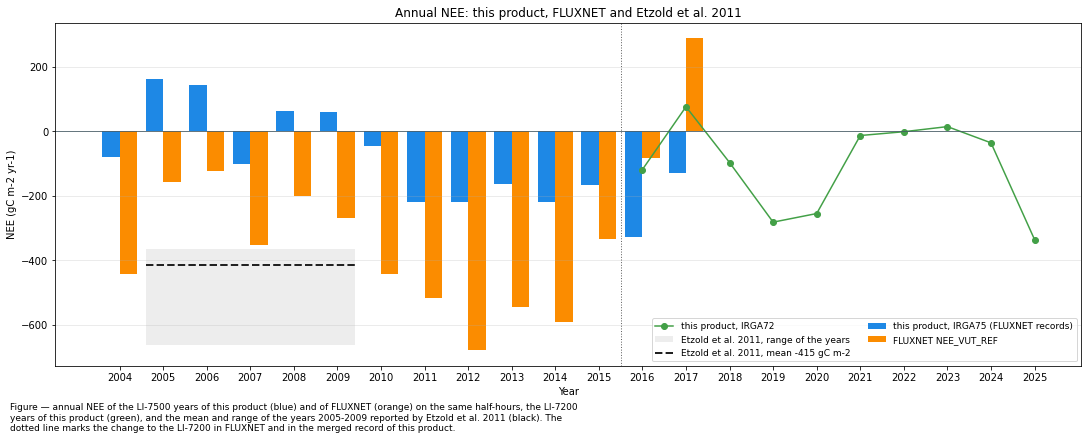

In [10]:
fig, ax = plt.subplots(figsize=(15, 6), dpi=72, layout="constrained")
_x = annual.index.to_numpy()
ax.bar(_x - 0.2, annual['ours, FLUXNET records'], width=0.4, color=COLORS['ours'],
       label="this product, IRGA75 (FLUXNET records)")
ax.bar(_x + 0.2, annual['FLUXNET (HH)'], width=0.4, color=COLORS['FLUXNET'],
       label="FLUXNET NEE_VUT_REF")
_a72 = annual72.drop('mean')['IRGA72 (ours)']
ax.plot(_a72.index, _a72, color=COLORS['IRGA72'], marker='o', lw=1.5, label="this product, IRGA72")
ax.fill_between([ETZOLD_YEARS[0] - 0.4, ETZOLD_YEARS[1] + 0.4], *ETZOLD_RANGE, color=COLORS['study2011'],
                alpha=0.08, lw=0, label="Etzold et al. 2011, range of the years")
ax.hlines(ETZOLD_MEAN, ETZOLD_YEARS[0] - 0.4, ETZOLD_YEARS[1] + 0.4, color=COLORS['study2011'], lw=2,
          ls='--', label=f"Etzold et al. 2011, mean {ETZOLD_MEAN} {units_sum}")
ax.axhline(0, color='#455A64', lw=0.8)
ax.axvline(2015.5, color='#616161', lw=1, ls=':')
ax.set_xticks(range(FIRST_YEAR, IRGA72_YEARS[1] + 1))
ax.set_xlabel("Year")
ax.set_ylabel(f"NEE ({units_sum} yr-1)")
ax.set_title("Annual NEE: this product, FLUXNET and Etzold et al. 2011")
ax.grid(alpha=0.3, axis='y')
ax.legend(fontsize=9, ncol=2, loc='lower right')
figcap(fig, "annual NEE of the LI-7500 years of this product (blue) and of FLUXNET (orange) on the "
            "same half-hours, the LI-7200 years of this product (green), and the mean and range "
            "of the years 2005-2009 reported by Etzold et al. 2011 (black). The dotted line marks "
            "the change to the LI-7200 in FLUXNET and in the merged record of this product.")
fig.show()

</br>

# Comparison with FLUXNET

The FLUXNET release for CH-Lae was built from the earlier product FP2021: for 2004-2015 from the
LI-7500 flux corrected for self-heating, for 2016-2017 from the LI-7200 flux. FLUXNET then applied
its own USTAR filter and gap-filling (MDS). Here the two records are compared half-hour by
half-hour, on the half-hours FLUXNET covers.

Each half-hour falls in one of four classes:

- **A** both measured
- **B** measured in this product only (FLUXNET filled it)
- **C** measured in FLUXNET only (this product filled it)
- **D** both filled

The annual difference is the sum of the differences in the four classes, by day and by night.

## Record classes

### 📋 Table: annual difference by record class, day and night

In [11]:
_g = c.groupby([_yc, 'cls', 'night'])['diff'].sum().unstack(['cls', 'night']) * UMOL_TO_GC
_g = _g.reindex(columns=pd.MultiIndex.from_product([list(CLASSES), [False, True]]))
_g.columns = flat(_g.columns)
_g['total'] = _g.sum(axis=1)
_g.index.name = 'YEAR'
by_class = _g
display(styled(by_class, caption=f"ours minus FLUXNET per year in {units_sum}, split by record class "
                                 f"(A both measured, B ours measured only, C FLUXNET measured only, D both "
                                 f"filled) and by day and night (FLUXNET NIGHT). The columns add up to "
                                 f"'total', the difference of the annual sums",
               subset=[col for col in by_class.columns if col != 'total']))

Table — ours minus FLUXNET per year in gC m-2, split by record class (A both measured, B ours
measured only, C FLUXNET measured only, D both filled) and by day and night (FLUXNET NIGHT). The
columns add up to 'total', the difference of the annual sums



,"A, day","A, night","B, day","B, night","C, day","C, night","D, day","D, night",total
YEAR,,,,,,,,,
2004,-10,7,0,-1,21,52,62,233,365
2005,4,19,25,9,16,26,52,170,322
2006,-10,30,17,9,13,33,-30,206,268
2007,-28,24,-2,13,12,36,46,150,251
2008,-35,30,6,18,16,34,28,167,265
2009,3,22,3,13,9,48,6,224,329
2010,-5,26,17,14,9,51,70,215,397
2011,-5,25,15,7,20,38,43,155,299
2012,8,15,7,7,18,41,89,273,461


In the LI-7500 years most of the difference comes from class D at night: nights that both products
gap-fill, and that this product fills higher than FLUXNET. The measured nights (classes A, B and C)
add smaller positive amounts. By day the classes partly cancel.

### 📋 Table: share of records per class

In [12]:
share_cls = c.groupby(_yc)['cls'].value_counts(normalize=True).unstack().reindex(columns=list(CLASSES)) * 100
share_cls.columns = [f"{k} {v} (%)" for k, v in CLASSES.items()]
share_cls.index.name = 'YEAR'
display(styled(share_cls, caption="share of the half-hours FLUXNET covers that fall in each record class, "
                                  "per year", fmt="{:.1f}", cmap='Blues', center=False))

Table — share of the half-hours FLUXNET covers that fall in each record class, per year



,A both measured (%),B ours measured only (%),C FLUXNET measured only (%),D both filled (%)
YEAR,,,,
2004,30.5,8.0,3.1,58.4
2005,28.9,7.4,4.5,59.2
2006,27.4,10.8,2.2,59.7
2007,31.8,9.6,2.4,56.3
2008,32.6,9.0,2.5,55.9
2009,30.3,8.3,3.8,57.6
2010,29.6,6.4,5.9,58.1
2011,32.0,7.0,4.6,56.4
2012,26.6,7.1,4.1,62.2


More than half of every year is filled in both products. Class A, the half-hours on which the two
measurements can be compared directly, holds a minority of each year.

### 📋 Table: measured share by day and night

In [13]:
_n = c['night']
measured = pd.DataFrame({
    'ours, day (%)': c.loc[~_n, 'ours_meas'].groupby(_yc[~_n]).mean() * 100,
    'FLUXNET, day (%)': c.loc[~_n, 'flx_meas'].groupby(_yc[~_n]).mean() * 100,
    'ours, night (%)': c.loc[_n, 'ours_meas'].groupby(_yc[_n]).mean() * 100,
    'FLUXNET, night (%)': c.loc[_n, 'flx_meas'].groupby(_yc[_n]).mean() * 100,
})
measured.index.name = 'YEAR'
display(styled(measured, caption="share of measured half-hours per year in each product, by day and by "
                                 "night (FLUXNET NIGHT)", fmt="{:.1f}", cmap='Blues', center=False))

Table — share of measured half-hours per year in each product, by day and by night (FLUXNET NIGHT)



,"ours, day (%)","FLUXNET, day (%)","ours, night (%)","FLUXNET, night (%)"
YEAR,,,,
2004,47.5,41.5,27.6,24.1
2005,45.8,42.2,25.9,23.6
2006,46.4,36.1,29.1,22.3
2007,50.1,42.0,31.9,25.4
2008,50.5,43.4,31.9,26.0
2009,48.1,42.8,28.1,24.4
2010,44.5,44.3,26.7,25.9
2011,48.7,46.0,28.3,26.2
2012,42.7,38.9,23.8,21.7


This product keeps more measured half-hours than FLUXNET, by day and by night, in most years. Both
fill most of the nights.

### 📋 Table: mean value of the records both products fill

In [14]:
_dd = c[c['cls'] == 'D']
filled_d = _dd.groupby([_dd.index.year, 'night'])[['ours', 'flx']].mean().unstack('night')
filled_d.columns = flat([('ours' if a == 'ours' else 'FLUXNET', b) for a, b in filled_d.columns])
filled_d.index.name = 'YEAR'
display(styled(filled_d, caption=f"class D, half-hours both products gap-fill: mean NEE per year in {units}, "
                                 f"by day and night", fmt="{:.2f}"))

Table — class D, half-hours both products gap-fill: mean NEE per year in µmol m-2 s-1, by day and
night



,"ours, day","ours, night","FLUXNET, day","FLUXNET, night"
YEAR,,,,
2004,-1.73,3.65,-2.49,1.18
2005,-0.67,3.44,-1.19,2.08
2006,-1.08,3.41,-0.78,1.74
2007,-1.50,3.41,-1.99,2.14
2008,-0.75,3.69,-1.04,2.27
2009,-0.17,3.50,-0.23,1.67
2010,-1.26,3.08,-1.98,1.32
2011,-2.44,3.55,-2.91,2.27
2012,-2.47,3.30,-3.32,1.21


At night the gap-filling of this product gives a respiration well above that of FLUXNET in the
LI-7500 years. This difference, over the many filled nights, is the class-D night column of the
first table.

### 📋 Table: annual difference by season

In [15]:
_season = pd.Series(np.array(['DJF', 'DJF', 'MAM', 'MAM', 'MAM', 'JJA', 'JJA', 'JJA', 'SON', 'SON',
                              'SON', 'DJF'])[c.index.month - 1], index=c.index)
by_season = c.groupby([_yc, _season])['diff'].sum().unstack()[['DJF', 'MAM', 'JJA', 'SON']] * UMOL_TO_GC
by_season['total'] = by_season.sum(axis=1)
by_season.index.name = 'YEAR'
display(styled(by_season, caption=f"ours minus FLUXNET per year and season in {units_sum}. DJF is December, "
                                  f"January and February of the same calendar year",
               subset=['DJF', 'MAM', 'JJA', 'SON']))

Table — ours minus FLUXNET per year and season in gC m-2. DJF is December, January and February of
the same calendar year



,DJF,MAM,JJA,SON,total
YEAR,,,,,
2004,238,69,-16,74,365
2005,126,161,-13,47,322
2006,125,173,-93,63,268
2007,102,44,67,38,251
2008,196,11,46,12,265
2009,100,109,39,80,329
2010,133,100,42,122,397
2011,111,83,43,61,299
2012,56,98,145,162,461


In most of the LI-7500 years the difference is largest in winter (DJF).

## Correction on the shared measured records

On the class-A half-hours both products measured, so a difference between them comes from the
processing of the same raw flux. The correction of this product is known (`-BIAS_OPCO`). The
correction contained in FLUXNET is estimated as its `NEE` minus the `NEE` of this product before
correction, `FC + SC_SINGLE`. This implied correction also contains any other difference of the
Level-1 processing and of the storage term between FP2021 and this product.

### 📋 Table: correction added on the shared measured records

In [16]:
_a = c[c['cls'] == 'A']
corr_a = _a.groupby([_a.index.year, 'night'])[['diff', 'opco', 'flx_implied']].mean().unstack('night')
corr_a.columns = flat([({'diff': 'ours minus FLUXNET', 'opco': 'correction, ours',
                         'flx_implied': 'correction, FLUXNET implied'}[a], b) for a, b in corr_a.columns])
corr_a['A records'] = _a.groupby(_a.index.year).size()
corr_a.index.name = 'YEAR'
_fmt = {col: "{:.2f}" for col in corr_a.columns}
_fmt['A records'] = "{:,.0f}"
display(styled(corr_a, caption=f"class A, half-hours both products measured: mean difference ours minus "
                               f"FLUXNET, and the mean correction each adds to the uncorrected flux, in "
                               f"{units}, by day and night",
               fmt=_fmt, subset=[col for col in corr_a.columns if col != 'A records']))

Table — class A, half-hours both products measured: mean difference ours minus FLUXNET, and the mean
correction each adds to the uncorrected flux, in µmol m-2 s-1, by day and night



,"ours minus FLUXNET, day","ours minus FLUXNET, night","correction, ours, day","correction, ours, night","correction, FLUXNET implied, day","correction, FLUXNET implied, night",A records
YEAR,,,,,,,
2004,-0.16,0.25,2.51,0.65,2.77,0.26,"4,279"
2005,0.06,0.55,3.00,0.78,3.15,0.29,"5,056"
2006,-0.15,0.84,2.80,0.93,3.04,0.21,"4,792"
2007,-0.36,0.58,2.46,0.50,2.98,0.16,"5,564"
2008,-0.43,0.71,2.75,0.65,3.36,0.17,"5,723"
2009,0.04,0.61,3.06,0.93,3.22,0.44,"5,300"
2010,-0.07,0.70,3.09,0.87,3.41,0.38,"5,185"
2011,-0.06,0.65,3.01,0.86,3.17,0.41,"5,601"
2012,0.12,0.49,2.82,0.71,2.92,0.37,"4,667"


By day the two corrections are of similar size and the products agree closely. At night the
correction of this product is larger than the one implied in FLUXNET, and this product is higher by
about the difference of the two corrections. In 2016 and 2017, when FLUXNET uses the LI-7200, the
FLUXNET-implied value is the difference between the two analysers rather than a correction.

## Night levels

### 📋 Table: mean nighttime NEE per year

In [17]:
_cn = c[c['night']]
_yn = _cn.index.year
nights_year = pd.DataFrame({
    'ours, measured': _cn.loc[_cn['ours_meas'], 'ours'].groupby(_yn[_cn['ours_meas']]).mean(),
    'FLUXNET, measured': _cn.loc[_cn['flx_meas'], 'flx'].groupby(_yn[_cn['flx_meas']]).mean(),
    'ours, all nights': _cn['ours'].groupby(_yn).mean(),
    'FLUXNET, all nights': _cn['flx'].groupby(_yn).mean(),
})
nights_year.index.name = 'YEAR'
display(styled(nights_year, caption=f"mean nighttime NEE per year in {units}: the measured nights of each "
                                    f"product, and all nights including the gap-filled ones",
               fmt="{:.2f}", cmap='Reds', center=False))

Table — mean nighttime NEE per year in µmol m-2 s-1: the measured nights of each product, and all
nights including the gap-filled ones



,"ours, measured","FLUXNET, measured","ours, all nights","FLUXNET, all nights"
YEAR,,,,
2004,3.92,2.29,3.70,1.59
2005,3.52,2.53,3.44,2.20
2006,3.81,2.52,3.50,1.96
2007,3.96,2.78,3.58,2.35
2008,4.06,2.87,3.80,2.43
2009,3.33,1.82,3.44,1.74
2010,3.70,1.99,3.22,1.53
2011,4.19,2.85,3.70,2.45
2012,3.63,2.29,3.36,1.50


The measured nights of FLUXNET are lower than those of this product in the LI-7500 years, and its
gap-filling, which learns from them, fills the nights lower as well.

### 📋 Table: monthly night means 2004-2015 per class

In [18]:
_p = c[(c.index.year <= LI7500_ONLY[1]) & c['night']]
_mo = _p.index.month


def _mean(sel, col):
    return _p.loc[sel, col].groupby(_mo[sel]).mean()


nights_month = pd.DataFrame({
    'ours, measured': _mean(_p['ours_meas'], 'ours'),
    'ours, filled': _mean(~_p['ours_meas'], 'ours'),
    'FLUXNET, measured': _mean(_p['flx_meas'], 'flx'),
    'FLUXNET, filled': _mean(~_p['flx_meas'], 'flx'),
    'A: ours': _mean(_p['cls'] == 'A', 'ours'),
    'A: FLUXNET': _mean(_p['cls'] == 'A', 'flx'),
    'C: ours (filled)': _mean(_p['cls'] == 'C', 'ours'),
    'C: FLUXNET (measured)': _mean(_p['cls'] == 'C', 'flx'),
    'D: ours': _mean(_p['cls'] == 'D', 'ours'),
    'D: FLUXNET': _mean(_p['cls'] == 'D', 'flx'),
    'ours filled (%)': (~_p['ours_meas']).groupby(_mo).mean() * 100,
    'FLUXNET filled (%)': (~_p['flx_meas']).groupby(_mo).mean() * 100,
})
# The LI-7200 of this product, 2016-2025, with its own night flag.
_r = r72[r72['night']]
nights_month['IRGA72, measured'] = _r.loc[_r['meas'], varname].groupby(_r.index.month[_r['meas']]).mean()
nights_month['IRGA72, all nights'] = _r[varname].groupby(_r.index.month).mean()
nights_month.index = [calendar.month_abbr[m] for m in nights_month.index]
nights_month.index.name = 'MONTH'
_vals = [col for col in nights_month.columns if '%' not in col]
_fmt = {col: "{:.2f}" for col in _vals}
_fmt.update({col: "{:.0f}" for col in nights_month.columns if '%' in col})
display(styled(nights_month, caption=f"mean nighttime NEE per calendar month over {LI7500_ONLY[0]}-"
                                     f"{LI7500_ONLY[1]} in {units}: measured and filled nights of each "
                                     f"product, and the nights of classes A, C and D, with the share of "
                                     f"filled nights. The last two columns are the LI-7200 of this product, "
                                     f"{IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, by its own NIGHTTIME flag",
               fmt=_fmt, subset=_vals, cmap='Reds', center=False))

Table — mean nighttime NEE per calendar month over 2004-2015 in µmol m-2 s-1: measured and filled
nights of each product, and the nights of classes A, C and D, with the share of filled nights. The
last two columns are the LI-7200 of this product, 2016-2025, by its own NIGHTTIME flag



,"ours, measured","ours, filled","FLUXNET, measured","FLUXNET, filled",A: ours,A: FLUXNET,C: ours (filled),C: FLUXNET (measured),D: ours,D: FLUXNET,ours filled (%),FLUXNET filled (%),"IRGA72, measured","IRGA72, all nights"
MONTH,,,,,,,,,,,,,,
Jan,3.15,2.72,1.55,0.33,3.39,2.62,2.55,-2.64,2.73,0.24,73,76,2.47,2.69
Feb,2.88,2.56,0.82,0.84,2.99,1.74,2.21,-1.90,2.59,0.85,75,77,2.49,2.61
Mar,2.41,2.74,1.05,0.43,2.50,1.59,2.64,-1.65,2.74,0.37,70,74,2.66,2.79
Apr,3.54,3.51,2.32,1.63,3.89,3.24,3.42,-5.67,3.52,1.58,66,72,3.71,3.62
May,4.90,4.09,3.94,2.46,5.28,4.78,4.28,-2.16,4.08,2.30,67,72,4.23,4.15
Jun,5.06,4.57,4.58,4.33,5.44,5.06,4.69,-0.16,4.57,4.31,68,75,5.64,5.25
Jul,4.80,4.82,4.45,4.06,4.96,4.62,4.73,2.75,4.82,4.03,70,77,5.04,4.88
Aug,4.92,4.60,4.69,4.32,5.29,4.73,4.52,4.37,4.60,4.28,75,80,5.10,4.86
Sep,4.43,4.09,4.11,3.57,4.76,4.36,4.31,1.42,4.08,3.55,68,74,4.73,4.45


### 📊 Plot: monthly night levels

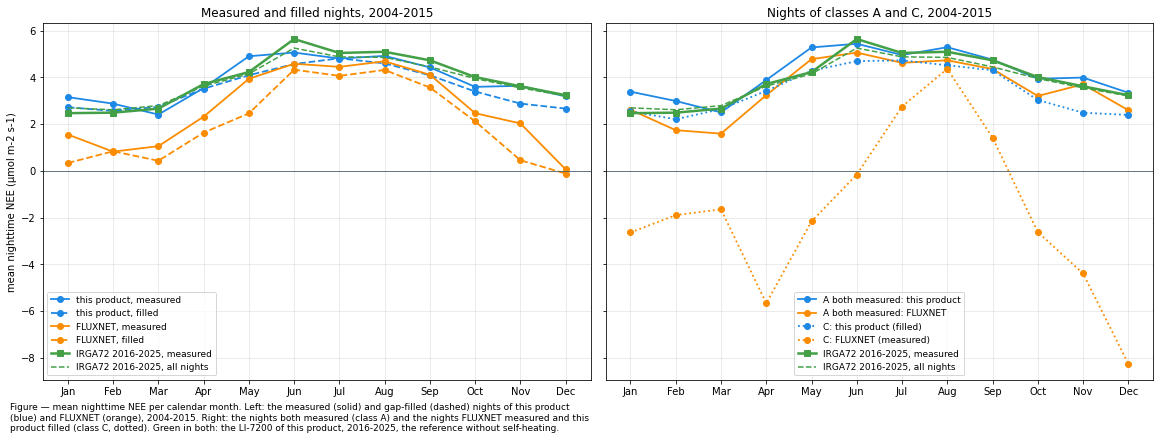

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6), dpi=72, layout="constrained", sharey=True)
_m = range(1, 13)
_nm = nights_month.set_axis(_m)
for _col, _c, _ls, _lab in (
        ('ours, measured', COLORS['ours'], '-', "this product, measured"),
        ('ours, filled', COLORS['ours'], '--', "this product, filled"),
        ('FLUXNET, measured', COLORS['FLUXNET'], '-', "FLUXNET, measured"),
        ('FLUXNET, filled', COLORS['FLUXNET'], '--', "FLUXNET, filled")):
    axs[0].plot(_m, _nm[_col], color=_c, ls=_ls, marker='o', lw=1.8, label=_lab)
for _col, _c, _ls, _lab in (
        ('A: ours', COLORS['ours'], '-', "A both measured: this product"),
        ('A: FLUXNET', COLORS['FLUXNET'], '-', "A both measured: FLUXNET"),
        ('C: ours (filled)', COLORS['ours'], ':', "C: this product (filled)"),
        ('C: FLUXNET (measured)', COLORS['FLUXNET'], ':', "C: FLUXNET (measured)")):
    axs[1].plot(_m, _nm[_col], color=_c, ls=_ls, marker='o', lw=1.8, label=_lab)
for _ax in axs:
    _ax.plot(_m, _nm['IRGA72, measured'], color=COLORS['IRGA72'], lw=2.5, marker='s',
             label=f"IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, measured")
    _ax.plot(_m, _nm['IRGA72, all nights'], color=COLORS['IRGA72'], lw=1.5, ls='--',
             label=f"IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, all nights")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
    month_axis(_ax)
axs[0].set_ylabel(f"mean nighttime NEE ({units})")
axs[0].set_title(f"Measured and filled nights, {LI7500_ONLY[0]}-{LI7500_ONLY[1]}")
axs[1].set_title(f"Nights of classes A and C, {LI7500_ONLY[0]}-{LI7500_ONLY[1]}")
figcap(fig, f"mean nighttime NEE per calendar month. Left: the measured (solid) and gap-filled (dashed) "
            f"nights of this product (blue) and FLUXNET (orange), {LI7500_ONLY[0]}-{LI7500_ONLY[1]}. "
            f"Right: the nights both measured (class A) and the nights FLUXNET measured and this "
            f"product filled (class C, dotted). Green in both: the LI-7200 of this product, "
            f"{IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}, the reference without self-heating.")
fig.show()

From late autumn to early spring the FLUXNET nights, measured and filled, lie well below those of
this product and of the LI-7200. The class-C nights, which FLUXNET keeps and this product removes,
are on average negative from autumn to spring: apparent nighttime uptake, which the tests of
negative nighttime values and the outlier tests of this product remove (Level 3.2). In summer the
products and the LI-7200 are close.

### 📋 Table: nights by USTAR class

In [20]:
_q = c[(c.index.year <= LI7500_ONLY[1]) & c['night']].copy()
_q['USTAR class (m s-1)'] = pd.cut(_q['USTAR'], USTAR_BINS)
by_ustar = _q.groupby('USTAR class (m s-1)', observed=True).agg(
    nights=('ours', 'size'), ours_meas=('ours_meas', 'mean'), flx_meas=('flx_meas', 'mean'),
    l32=('ours_l32', 'mean'))
by_ustar['ours_meas'] *= 100
by_ustar['flx_meas'] *= 100
by_ustar.columns = ['night records', 'ours measured (%)', 'FLUXNET measured (%)',
                    f'ours before USTAR filter, mean ({units})']
by_ustar.index = by_ustar.index.astype(str)
display(styled(by_ustar, caption=f"nights {LI7500_ONLY[0]}-{LI7500_ONLY[1]} by USTAR of this product: the "
                                 f"share each product keeps as measured, and the mean NEE of this product "
                                 f"after the outlier tests and before the USTAR filter. The USTAR threshold "
                                 f"of this product is {USTAR_CUT_50} m s-1",
               fmt={'night records': "{:,.0f}", 'ours measured (%)': "{:.0f}",
                    'FLUXNET measured (%)': "{:.0f}", f'ours before USTAR filter, mean ({units})': "{:.2f}"},
               cmap=None))

Table — nights 2004-2015 by USTAR of this product: the share each product keeps as measured, and the
mean NEE of this product after the outlier tests and before the USTAR filter. The USTAR threshold of
this product is 0.304 m s-1



,night records,ours measured (%),FLUXNET measured (%),"ours before USTAR filter, mean (µmol m-2 s-1)"
USTAR class (m s-1),,,,
"(0.0, 0.1]","5,127",0,0,0.27
"(0.1, 0.2]","17,300",0,0,0.62
"(0.2, 0.3]","15,650",0,5,1.19
"(0.3, 0.4]","12,540",48,27,2.20
"(0.4, 0.6]","20,153",51,42,3.35
"(0.6, 5.0]","24,215",47,44,5.00


This product keeps no night below its threshold. FLUXNET keeps a few nights in the class just below
it and fewer in the classes above, consistent with a variable threshold that is higher in most
years. Before the USTAR filter the nighttime `NEE` rises with USTAR in every class. Below the
threshold it is low, the signature of respiration that the turbulence does not carry to the sensor;
above it the rise also reflects the season.

### 📋 Table: 2016-2017 nights, LI-7500, LI-7200 and FLUXNET

In [21]:
_e = c[c.index.year >= PARALLEL_YEARS[0]]
_e = _e.join(nee72[[varname]].rename(columns={varname: 'ours72'}))
_en = _e[_e['night']]
_ye, _yen = _e.index.year, _en.index.year
parallel = pd.DataFrame({
    'night, IRGA75 (ours)': _en['ours'].groupby(_yen).mean(),
    'night, IRGA72 (ours)': _en['ours72'].groupby(_yen).mean(),
    'night, FLUXNET': _en['flx'].groupby(_yen).mean(),
    'year, IRGA75 (ours)': per_year(_e['ours']),
    'year, IRGA72 (ours)': per_year(_e['ours72']),
    'year, FLUXNET': per_year(_e['flx']),
})
parallel.index.name = 'YEAR'
display(styled(parallel, caption=f"the parallel years: mean nighttime NEE ({units}, all nights) and annual "
                                 f"NEE ({units_sum}) of the LI-7500 and the LI-7200 of this product, and of "
                                 f"FLUXNET, which uses the LI-7200 in these years",
               fmt={col: ("{:.2f}" if col.startswith('night') else "{:.0f}") for col in parallel.columns},
               cmap=None))

Table — the parallel years: mean nighttime NEE (µmol m-2 s-1, all nights) and annual NEE (gC m-2) of
the LI-7500 and the LI-7200 of this product, and of FLUXNET, which uses the LI-7200 in these years



,"night, IRGA75 (ours)","night, IRGA72 (ours)","night, FLUXNET","year, IRGA75 (ours)","year, IRGA72 (ours)","year, FLUXNET"
YEAR,,,,,,
2016,3.39,3.74,4.24,-326,-119,-81
2017,3.17,3.76,5.35,-128,76,288


In the parallel years the LI-7200 nights of this product are higher than its LI-7500 nights, and
the FLUXNET nights, built on the LI-7200, are higher still. FLUXNET has less annual uptake than both
records of this product in these years. Its difference to the LI-7200 of this product is not
investigated here.

</br>

# Comparison with Etzold et al. (2011)

Etzold et al. (2011) report the `NEE` of 2005-2009 from the same LI-7500. Their processing differs
from this product in several steps. The one with the largest effect on the annual sum is the
self-heating correction, which is recomputed here for the flux of this product.

## 📋 Table: processing compared

In [22]:
_e9 = d.loc[str(ETZOLD_YEARS[0]):str(ETZOLD_YEARS[1])].copy()
_meas_night = _e9.loc[_e9['night'], 'ours_meas'].mean() * 100
_meas_night_flx = _e9.loc[_e9['night'], 'flx_meas'].mean() * 100
_prod = dict(PRODUCT_METHODS)
_prod['measured nights (%)'] = f"{_meas_night:.0f} (FLUXNET: {_meas_night_flx:.0f})"
methods = pd.DataFrame({'Etzold et al. 2011 (p. 1297)': ETZOLD_METHODS, 'this product': _prod})
methods.index.name = 'step'
display(styled(methods, caption=f"processing of Etzold et al. 2011 and of this product. The measured share "
                                f"of the nights of this product is computed here for "
                                f"{ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} with the FLUXNET night flag",
               cmap=None))

Table — processing of Etzold et al. 2011 and of this product. The measured share of the nights of
this product is computed here for 2005-2009 with the FLUXNET night flag



,Etzold et al. 2011 (p. 1297),this product
step,,
density correction,WPL,"WPL, in EddyPro (Level 1)"
self-heating correction,"Burba et al. (2008), with the surface temperatures and fraction of Järvi et al. (2009)",opco: heating and WPL thermal terms with coefficients fitted to the LI-7200 in 2016-2017 (Level 1.1)
large winter fluxes (±15 µmol m-2 s-1),"kept in the data, excluded from the gap-filling fits",absolute limits ±50 µmol m-2 s-1 and outlier tests (Level 3.2)
negative nighttime values,"removed, together with as many positive ones (trimmed)",removed where clearly below zero: single records and whole nights (Level 3.2)
gap-filling,"light response by day, Lloyd-Taylor at night, running mean below 0 °C",XGBoost (Level 4.1)
USTAR threshold (m s-1),0.3,"0.304 (CUT_50, constant)"
measured nights (%),24,29 (FLUXNET: 24)


## The two self-heating corrections

The correction of Burba et al. (2008) adds a heat-flux term computed from the instrument surface
temperature, the CO2 density and the aerodynamic resistance; Järvi et al. (2009) scale it by a fixed
fraction (0.085) and estimate the surface temperature from air temperature. It is computed here from
the input of the flux chain with the equation of *Helpers*, the sonic temperature standing in for air
temperature. opco is the correction of this product (Level 1.1).

### 📋 Table: distribution of the corrections per half-hour

In [23]:
_dist = {}
for _col, _lab in (('opco', 'opco (this product)'), ('burba', 'Burba et al. 2008 / Järvi et al. 2009')):
    _s = _e9[_col].dropna()
    _dist[_lab] = {'records': len(_s), 'mean': _s.mean(), 'median': _s.median(),
                   'P01': _s.quantile(0.01), 'P99': _s.quantile(0.99),
                   'above 5 (%)': (_s > 5).mean() * 100}
corr_dist = pd.DataFrame(_dist).T
display(styled(corr_dist, caption=f"the two corrections on every half-hour with an uncorrected flux, "
                                  f"{ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}, in {units}: mean, median, 1st and "
                                  f"99th percentile, and the share above 5 {units}",
               fmt={'records': "{:,.0f}", 'mean': "{:.2f}", 'median': "{:.2f}", 'P01': "{:.2f}",
                    'P99': "{:.2f}", 'above 5 (%)': "{:.2f}"}, cmap=None))

Table — the two corrections on every half-hour with an uncorrected flux, 2005-2009, in µmol m-2 s-1:
mean, median, 1st and 99th percentile, and the share above 5 µmol m-2 s-1



,records,mean,median,P01,P99,above 5 (%)
opco (this product),"74,645",1.68,1.02,-3.06,9.73,6.61
Burba et al. 2008 / Järvi et al. 2009,"81,503",0.80,0.54,0.02,4.51,0.85


The correction of Burba et al. (2008) has a long upper tail: a few half-hours with a large USTAR
relative to the wind speed get a large correction. Its mean per month is therefore larger than its
median, and the median is used below to apply it to every half-hour; the mean is shown as a
sensitivity.

### 📋 Table: correction per month, day and night

In [24]:
_mo9 = _e9.index.month
corr_month = pd.concat({
    'opco, mean': _e9.groupby([_mo9, 'night'])['opco'].mean().unstack('night'),
    'Burba, mean': _e9.groupby([_mo9, 'night'])['burba'].mean().unstack('night'),
    'Burba, median': _e9.groupby([_mo9, 'night'])['burba'].median().unstack('night'),
}, axis=1)
corr_month.columns = flat(corr_month.columns)
corr_month.index = [calendar.month_abbr[m] for m in corr_month.index]
corr_month.index.name = 'MONTH'
display(styled(corr_month, caption=f"the correction each method adds per half-hour, by calendar month and "
                                   f"by day and night, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}, in {units}. "
                                   f"Burba: the correction of Burba et al. 2008 with the fraction of Järvi "
                                   f"et al. 2009", fmt="{:.2f}", cmap='Reds', center=False))

Table — the correction each method adds per half-hour, by calendar month and by day and night,
2005-2009, in µmol m-2 s-1. Burba: the correction of Burba et al. 2008 with the fraction of Järvi et
al. 2009



,"opco, mean, day","opco, mean, night","Burba, mean, day","Burba, mean, night","Burba, median, day","Burba, median, night"
MONTH,,,,,,
Jan,3.52,1.08,1.18,0.93,0.83,0.56
Feb,3.86,1.04,1.06,0.84,0.81,0.52
Mar,3.04,0.73,1.05,0.78,0.88,0.55
Apr,2.81,0.51,0.99,0.56,0.71,0.35
May,2.30,0.44,0.87,0.49,0.66,0.33
Jun,2.19,0.40,0.81,0.46,0.63,0.29
Jul,1.95,0.35,0.81,0.42,0.63,0.25
Aug,2.06,0.36,0.73,0.41,0.55,0.24
Sep,2.29,0.41,0.77,0.49,0.57,0.28


### 📊 Plot: correction per month, day and night

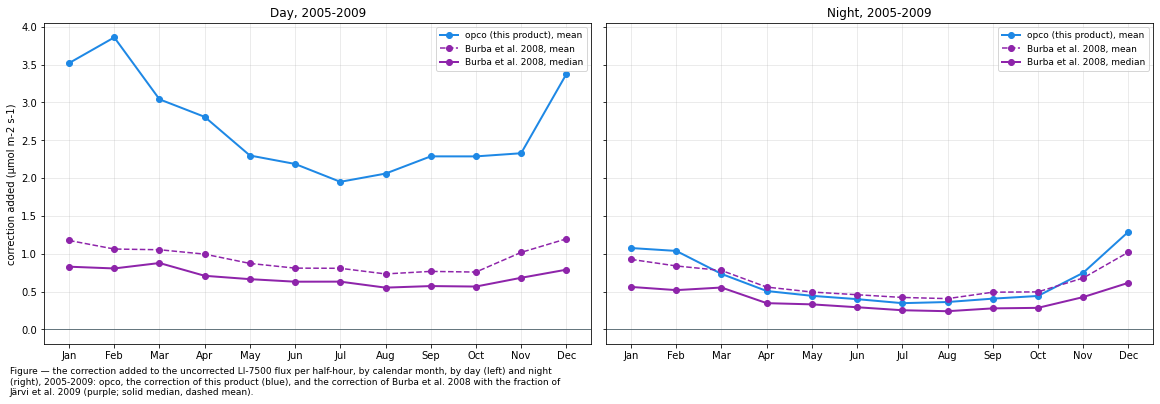

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5), dpi=72, layout="constrained", sharey=True)
_m = range(1, 13)
for _ax, _tod in zip(axs, ('day', 'night')):
    _ax.plot(_m, corr_month[f"opco, mean, {_tod}"].to_numpy(), color=COLORS['ours'], marker='o', lw=2,
             label="opco (this product), mean")
    _ax.plot(_m, corr_month[f"Burba, mean, {_tod}"].to_numpy(), color=COLORS['burba'], marker='o', lw=1.5,
             ls='--', label="Burba et al. 2008, mean")
    _ax.plot(_m, corr_month[f"Burba, median, {_tod}"].to_numpy(), color=COLORS['burba'], marker='o',
             lw=2, label="Burba et al. 2008, median")
    _ax.axhline(0, color='#455A64', lw=0.8)
    _ax.set_title(f"{_tod.capitalize()}, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}")
    _ax.grid(alpha=0.3)
    _ax.legend(fontsize=9)
    month_axis(_ax)
axs[0].set_ylabel(f"correction added ({units})")
figcap(fig, f"the correction added to the uncorrected LI-7500 flux per half-hour, by calendar month, by "
            f"day (left) and night (right), {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}: opco, the correction "
            f"of this product (blue), and the correction of Burba et al. 2008 with the fraction of "
            f"Järvi et al. 2009 (purple; solid median, dashed mean).")
fig.show()

By day opco adds several times as much as the correction of Burba et al. (2008), in every month.
At night the two are closer: from April to October the mean of the correction of Burba et al.
(2008) is about as large as opco and its median is smaller; in winter opco is the larger of the
two.

## Monthly and seasonal NEE, 2005-2009

To compare with Etzold et al. (2011), the flux of this product is shown in four versions: as
published (*ours*, with opco); without opco; and with the correction of Burba et al. (2008) in place
of opco, with its median or its mean per month. A gap-filled value is learned from corrected
measured values and carries the correction as well, so both corrections are removed or added on
every half-hour, as the mean (opco) or median (Burba) of each calendar month by day and by night.

### 📋 Table: mean monthly NEE

In [26]:
_e9['opco_clim'] = month_night_climatology(_e9, 'opco', 'mean')
_e9['burba_clim'] = month_night_climatology(_e9, 'burba', 'median')
_e9['burba_clim_mean'] = month_night_climatology(_e9, 'burba', 'mean')
_e9['ours_noopco'] = _e9['ours'] - _e9['opco_clim']
_e9['ours_burba'] = _e9['ours_noopco'] + _e9['burba_clim']
_e9['ours_burba_mean'] = _e9['ours_noopco'] + _e9['burba_clim_mean']

LINES = {
    'Etzold et al. 2011 (Fig. 5)': 'Etzold et al. 2011, Fig. 5, read by eye',
    'ours': 'this product, IRGA75, with opco',
    'ours without opco': 'this product, IRGA75, without opco',
    'ours with Burba': 'this product, IRGA75, with the correction of Burba et al. 2008 (median)',
    'ours with Burba (mean)': 'this product, IRGA75, with the correction of Burba et al. 2008 (mean)',
    'FLUXNET': 'FLUXNET NEE_VUT_REF',
    f'IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}': 'this product, IRGA72',
}
monthly = pd.DataFrame({
    'Etzold et al. 2011 (Fig. 5)': pd.Series(ETZOLD_FIG5, dtype=float),
    'ours': mean_monthly_sums(_e9['ours']),
    'ours without opco': mean_monthly_sums(_e9['ours_noopco']),
    'ours with Burba': mean_monthly_sums(_e9['ours_burba']),
    'ours with Burba (mean)': mean_monthly_sums(_e9['ours_burba_mean']),
    'FLUXNET': mean_monthly_sums(_e9['flx']),
    f'IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}': mean_monthly_sums(r72[varname]),
    'opco added': mean_monthly_sums(_e9['opco_clim']),
    'Burba added': mean_monthly_sums(_e9['burba_clim']),
}).sort_index()
_show = monthly.copy()
_show.index = [calendar.month_abbr[m] for m in _show.index]
_show.loc['year'] = monthly.sum()
_show.index.name = 'MONTH'
display(styled(_show, caption=f"mean monthly NEE in {units_sum}, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} unless "
                              f"stated: Etzold et al. 2011 read from their Fig. 5 (±{ETZOLD_FIG5_ACCURACY} "
                              f"{units_sum}, least certain in November to March); this product with opco, "
                              f"without it, and with the correction of Burba et al. 2008 in its place; "
                              f"FLUXNET; the LI-7200 of this product over {IRGA72_YEARS[0]}-"
                              f"{IRGA72_YEARS[1]}. The last two columns are the monthly sums of the two "
                              f"corrections as applied. The Fig. 5 values sum to "
                              f"{sum(ETZOLD_FIG5.values())} against the published {ETZOLD_MEAN}",
               subset=[col for col in _show.columns if 'added' not in col]))

Table — mean monthly NEE in gC m-2, 2005-2009 unless stated: Etzold et al. 2011 read from their Fig.
5 (±10 gC m-2, least certain in November to March); this product with opco, without it, and with the
correction of Burba et al. 2008 in its place; FLUXNET; the LI-7200 of this product over 2016-2025.
The last two columns are the monthly sums of the two corrections as applied. The Fig. 5 values sum
to -395 against the published -415



,Etzold et al. 2011 (Fig. 5),ours,ours without opco,ours with Burba,ours with Burba (mean),FLUXNET,IRGA72 2016-2025,opco added,Burba added
MONTH,,,,,,,,,
Jan,35,99,34,55,67,65,82,65,21
Feb,35,75,8,27,35,49,60,67,19
Mar,35,55,-6,17,23,10,37,61,23
Apr,-5,35,-22,-5,3,-2,6,57,17
May,-110,-80,-133,-115,-109,-97,-101,53,18
Jun,-155,-111,-160,-144,-139,-112,-145,50,16
Jul,-138,-91,-136,-120,-115,-103,-130,45,16
Aug,-105,-76,-120,-106,-101,-71,-81,45,14
Sep,-62,-41,-86,-72,-66,-39,-59,44,14


### 📋 Table: seasonal sums

In [27]:
seasons = season_sums(monthly)
seasons.loc['Etzold et al. 2011 (published)'] = [np.nan] * len(SEASONS) + [ETZOLD_MEAN]
seasons = seasons.loc[[*list(LINES)[:1], 'Etzold et al. 2011 (published)', *list(LINES)[1:],
                       'opco added', 'Burba added']]
display(styled(seasons, caption=f"mean NEE per season in {units_sum}, sums of the monthly means of the table "
                                f"above, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} unless stated. The published "
                                f"annual mean of Etzold et al. 2011 is {ETZOLD_MEAN} (range "
                                f"{ETZOLD_RANGE[0]} to {ETZOLD_RANGE[1]}). The rows without and with the "
                                f"other correction are approximations",
               subset=pd.IndexSlice[seasons.index[:-2], :]))

Table — mean NEE per season in gC m-2, sums of the monthly means of the table above, 2005-2009
unless stated. The published annual mean of Etzold et al. 2011 is -415 (range -662 to -366). The
rows without and with the other correction are approximations



,Nov-Mar,Apr+Oct,May-Sep,year
Etzold et al. 2011 (Fig. 5),175,0,-570,-395
Etzold et al. 2011 (published),-,-,-,-415
ours,393,72,-399,66
ours without opco,91,-27,-635,-572
ours with Burba,192,3,-558,-362
ours with Burba (mean),241,18,-529,-270
FLUXNET,183,19,-423,-221
IRGA72 2016-2025,374,38,-517,-105
opco added,302,99,236,638
Burba added,102,31,77,210


The flux of this product with the correction of Burba et al. (2008) in place of opco comes close to
the values Etzold et al. (2011) report, in the year and in each season. The remaining difference is
of the size of the reading accuracy of their figure and of the other processing steps. In winter
(November to March) the LI-7200 years agree with the opco-corrected flux and not with the smaller
correction. In summer (May to September) they lie between the two in the run shown. With the
monthly mean of the correction of Burba et al. (2008) in place of its median the flux shows less
uptake, so the result depends on how the long upper tail of that correction is treated.

### 📋 Table: annual NEE 2005-2009

In [28]:
_yr9 = pd.DataFrame({
    'ours': per_year(_e9['ours']),
    'ours without opco': per_year(_e9['ours_noopco']),
    'ours with Burba': per_year(_e9['ours_burba']),
    'FLUXNET': per_year(_e9['flx']),
})
years9 = pd.DataFrame({'mean': _yr9.mean(), 'most negative': _yr9.min(), 'least negative': _yr9.max()})
years9.loc['Etzold et al. 2011 (published)'] = [ETZOLD_MEAN, *ETZOLD_RANGE]
display(styled(years9, caption=f"annual NEE {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]} in {units_sum}: the mean of "
                               f"the five years and the most and least negative year. The correction "
                               f"climatology is the same in every year, so the spread of the rows without "
                               f"and with the other correction is that of the flux of this product"))

Table — annual NEE 2005-2009 in gC m-2: the mean of the five years and the most and least negative
year. The correction climatology is the same in every year, so the spread of the rows without and
with the other correction is that of the flux of this product



,mean,most negative,least negative
ours,66,-101,164
ours without opco,-572,-739,-474
ours with Burba,-362,-529,-264
FLUXNET,-221,-352,-124
Etzold et al. 2011 (published),-415,-662,-366


### 📊 Plot: mean monthly NEE

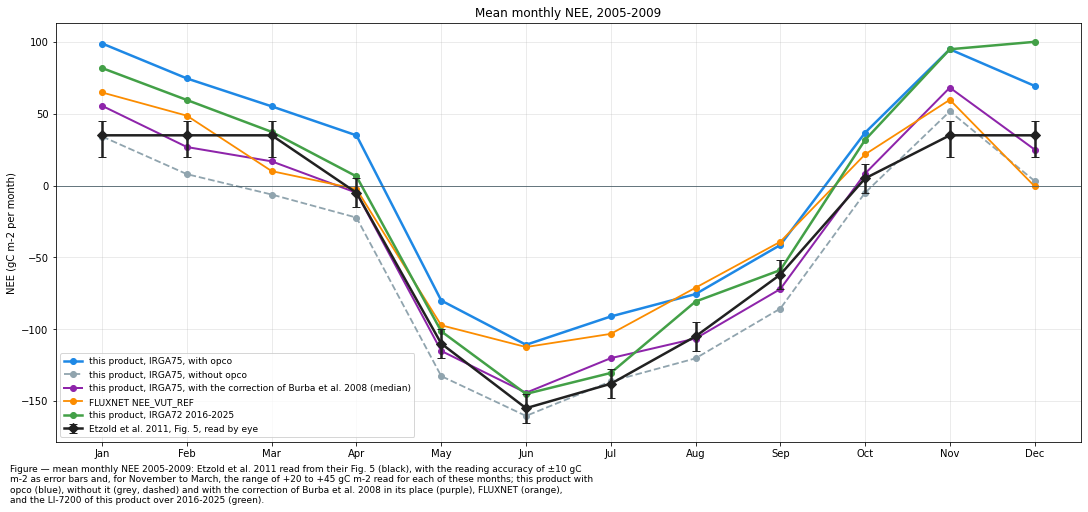

In [29]:
fig, ax = plt.subplots(figsize=(15, 7), dpi=72, layout="constrained")
_m = range(1, 13)
_fig5 = monthly['Etzold et al. 2011 (Fig. 5)']
# Error bars: the reading accuracy, and for the five winter months the range read from the figure.
_lo = pd.Series(float(ETZOLD_FIG5_ACCURACY), index=_fig5.index)
_hi = _lo.copy()
_lo[ETZOLD_FIG5_LEAST_CERTAIN] = _fig5[ETZOLD_FIG5_LEAST_CERTAIN] - ETZOLD_FIG5_WINTER_RANGE[0]
_hi[ETZOLD_FIG5_LEAST_CERTAIN] = ETZOLD_FIG5_WINTER_RANGE[1] - _fig5[ETZOLD_FIG5_LEAST_CERTAIN]
ax.errorbar(_m, _fig5, yerr=[_lo.to_numpy(), _hi.to_numpy()], color=COLORS['study2011'], marker='D',
            ms=7, lw=2.5, capsize=4, label=LINES['Etzold et al. 2011 (Fig. 5)'], zorder=5)
for _col, _c, _ls, _lw in (('ours', COLORS['ours'], '-', 2.5),
                           ('ours without opco', COLORS['noopco'], '--', 1.8),
                           ('ours with Burba', COLORS['burba'], '-', 2.0),
                           ('FLUXNET', COLORS['FLUXNET'], '-', 1.8),
                           (f'IRGA72 {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}', COLORS['IRGA72'], '-', 2.5)):
    _lab = LINES[_col] + (f" {IRGA72_YEARS[0]}-{IRGA72_YEARS[1]}" if _col.startswith('IRGA72') else "")
    ax.plot(_m, monthly[_col], color=_c, ls=_ls, lw=_lw, marker='o', label=_lab)
ax.axhline(0, color='#455A64', lw=0.8)
ax.set_ylabel(f"NEE ({units_sum} per month)")
ax.set_title(f"Mean monthly NEE, {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}")
ax.grid(alpha=0.3)
ax.legend(fontsize=9, loc='lower left')
month_axis(ax)
figcap(fig, f"mean monthly NEE {ETZOLD_YEARS[0]}-{ETZOLD_YEARS[1]}: Etzold et al. 2011 read from their "
            f"Fig. 5 (black), with the reading accuracy of ±{ETZOLD_FIG5_ACCURACY} {units_sum} as error "
            f"bars and, for November to March, the range of +{ETZOLD_FIG5_WINTER_RANGE[0]} to "
            f"+{ETZOLD_FIG5_WINTER_RANGE[1]} {units_sum} read for each of these months; this product with opco (blue), "
            f"without it (grey, dashed) and with the correction of Burba et al. 2008 in its place "
            f"(purple), FLUXNET (orange), and the LI-7200 of this product over {IRGA72_YEARS[0]}-"
            f"{IRGA72_YEARS[1]} (green).")
fig.show()

The seasonal course of the flux with the correction of Burba et al. (2008) follows that of Etzold
et al. (2011). opco raises every month by a similar amount, so the flux of this product has the same
shape at a higher level. The LI-7200 years follow this product in winter and lie between the two
corrections in summer.

</br>

# End of notebook

In [30]:
dt_string = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"Finished. {dt_string}")

Finished. 2026-10-30 15:38:39
